In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import re
import nltk
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [2]:
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [3]:
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

df = pd.read_csv(
    url,
    sep='\t',
    header=None,
    names=['label', 'text']
)

df.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:
df.shape

(5572, 2)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   5572 non-null   object
 1   text    5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [6]:
df['label'].value_counts()

,count
label,
ham,4825
spam,747


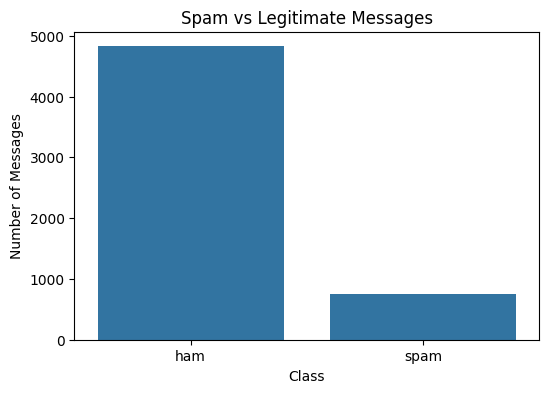

In [7]:
plt.figure(figsize=(6,4))

sns.countplot(
    x='label',
    data=df
)

plt.title("Spam vs Legitimate Messages")
plt.xlabel("Class")
plt.ylabel("Number of Messages")

plt.show()

In [8]:
df.isnull().sum()

,0
label,0
text,0


In [9]:
df.duplicated().sum()

np.int64(403)

In [10]:
df = df.drop_duplicates()

df = df.reset_index(drop=True)

In [11]:
df.shape

(5169, 2)

In [12]:
df['target'] = df['label'].map({
    'ham': 0,
    'spam': 1
})

In [13]:
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

In [14]:
def clean_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove numbers and special characters
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)

    # Split into words
    words = text.split()

    # Remove stopwords and lemmatize
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return ' '.join(words)

In [15]:
sample = "Congratulations! You WON $1000. Click www.example.com now!"

print("Original:")
print(sample)

print("\nCleaned:")
print(clean_text(sample))

Original:
Congratulations! You WON $1000. Click www.example.com now!

Cleaned:
congratulation click


In [16]:
df['clean_text'] = df['text'].apply(clean_text)

In [17]:
df[['text', 'clean_text']].head(10)

,text,clean_text
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah think go usf life around though
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darling week word back like fun st...
6,Even my brother is not like to speak with me. ...,even brother like speak treat like aid patent
7,As per your request 'Melle Melle (Oru Minnamin...,per request melle melle oru minnaminunginte nu...
8,WINNER!! As a valued network customer you have...,winner valued network customer selected receiv...
9,Had your mobile 11 months or more? U R entitle...,mobile month u r entitled update latest colour...


In [18]:
X = df['clean_text']
y = df['target']

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [20]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4135
Testing samples: 1034


In [21]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2
)

In [22]:
X_train_tfidf = tfidf.fit_transform(X_train)

In [23]:
X_test_tfidf = tfidf.transform(X_test)

In [24]:
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (4135, 5000)
Testing TF-IDF shape: (1034, 5000)


In [25]:
tfidf.fit_transform(X_train)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 36674 stored elements and shape (4135, 5000)>

In [26]:
tfidf.transform(X_test)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 8092 stored elements and shape (1034, 5000)>

In [27]:
nb_model = MultinomialNB()

nb_model.fit(
    X_train_tfidf,
    y_train
)

MultinomialNB()

In [28]:
nb_pred = nb_model.predict(X_test_tfidf)

In [29]:
svm_model = LinearSVC()

svm_model.fit(
    X_train_tfidf,
    y_train
)

LinearSVC()

In [30]:
svm_pred = svm_model.predict(X_test_tfidf)

In [31]:
lr_model = LogisticRegression(
    max_iter=1000
)

lr_model.fit(
    X_train_tfidf,
    y_train
)

LogisticRegression(max_iter=1000)

In [32]:
lr_pred = lr_model.predict(X_test_tfidf)

In [33]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_tfidf,
    y_train
)

RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)

In [34]:
rf_pred = rf_model.predict(X_test_tfidf)

In [35]:
models = {
    "Naive Bayes": nb_pred,
    "SVM": svm_pred,
    "Logistic Regression": lr_pred,
    "Random Forest": rf_pred
}

results = []

for name, predictions in models.items():

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    results.append([
        name,
        accuracy,
        precision,
        recall,
        f1
    ])

In [36]:
results_df = pd.DataFrame(
    results,
    columns=[
        'Model',
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score'
    ]
)

results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Naive Bayes,0.969052,1.000000,0.755725,0.860870
1,SVM,0.985493,0.975410,0.908397,0.940711
2,Logistic Regression,0.954545,0.956522,0.671756,0.789238
3,Random Forest,0.973888,0.972727,0.816794,0.887967


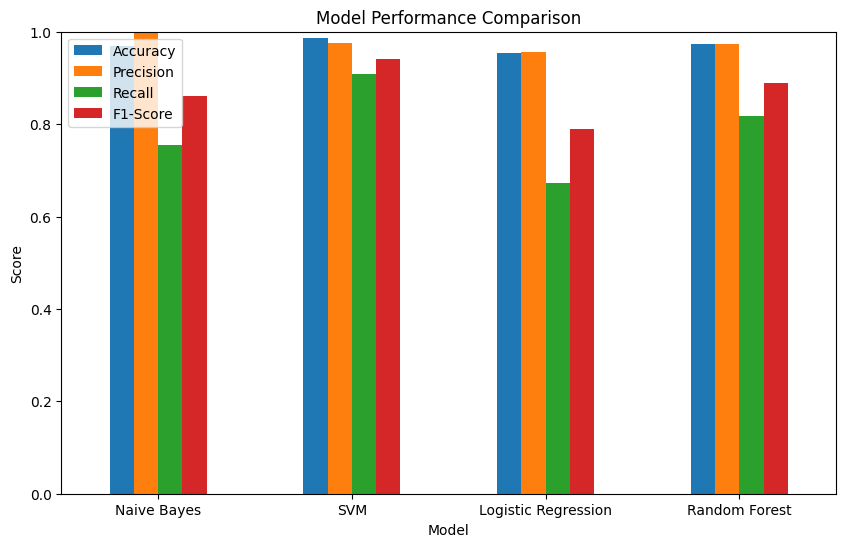

In [37]:
results_df.set_index('Model').plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)

plt.show()

In [38]:
best_model_name = results_df.loc[
    results_df['F1-Score'].idxmax(),
    'Model'
]

print("Best Model:", best_model_name)

Best Model: SVM


In [39]:
print(classification_report(
    y_test,
    svm_pred,
    target_names=['Legitimate', 'Spam']
))

              precision    recall  f1-score   support

  Legitimate       0.99      1.00      0.99       903
        Spam       0.98      0.91      0.94       131

    accuracy                           0.99      1034
   macro avg       0.98      0.95      0.97      1034
weighted avg       0.99      0.99      0.99      1034



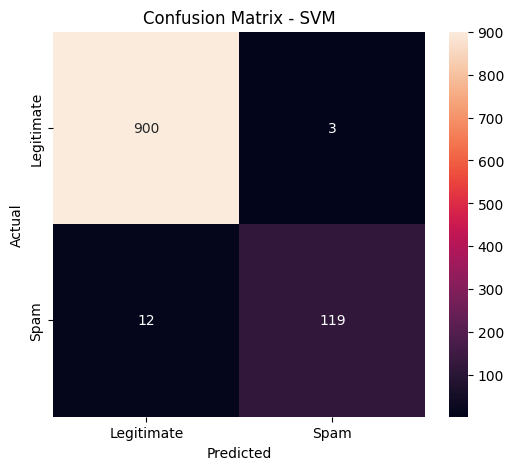

In [40]:
cm = confusion_matrix(
    y_test,
    svm_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=['Legitimate', 'Spam'],
    yticklabels=['Legitimate', 'Spam']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVM")

plt.show()

In [41]:
new_email = """
Congratulations! You have won $1000.
Click the link below to claim your prize immediately.
"""

In [42]:
cleaned_email = clean_text(new_email)

print(cleaned_email)

congratulation click link claim prize immediately


In [43]:
email_vector = tfidf.transform([cleaned_email])

In [47]:
prediction = svm_model.predict(email_vector)

if prediction[0] == 1:
    print("🚨 Spam Email ")
else:
    print("✅ Legitimate Email")

🚨 Spam Email 


In [48]:
new_email = """
Hi John,
Please find attached the project report.
Let me know if you have any questions.
We can discuss it in tomorrow's meeting.
"""

In [49]:
cleaned_email = clean_text(new_email)

email_vector = tfidf.transform([cleaned_email])

prediction = svm_model.predict(email_vector)

if prediction[0] == 1:
    print("🚨 Spam / Phishing Email")
else:
    print("✅ Legitimate Email")

✅ Legitimate Email
